In [ ]:
# this notebook was updated using ai to fit the report section format and setup

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import r2_score

sys.path.insert(0, str(Path("../scripts").resolve()))
from train_cnn import EDGES, GROUPS

DATA, OUT = Path("../data"), Path("../outputs")
FIG, TAB = OUT / "figures", OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

RUNS = {seed: f"cnn16s_seed{seed}" for seed in (0, 1, 2)}   # the frozen CNN, docs/FROZEN_SETTINGS.md
SPLITS = ["val", "test"]

COLOR = {"ridge": "#2a78d6", "CNN": "#eb6834"}   # the same colour for a model in every figure
MARKER = {"ridge": "o", "CNN": "^"}              # and a shape, so the figures survive greyscale printing
plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
                     "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})

def save(fig, name):
    # sized for a 7-inch-wide page: 300 dpi PNG for Word, PDF for LaTeX
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

def split_ages(split):
    seg = torch.load(DATA / f"segments_h1k_{split}.pt", weights_only=True)
    return pd.Series({t[4].removesuffix(".edf"): t[3] for t in seg})

def evaluate(age, pred):
    # the same columns as cell 5 of 01_baseline
    err = np.abs(pred - age)
    group = pd.cut(age, EDGES, right=False, labels=GROUPS)
    per_group = pd.Series(err).groupby(group, observed=False).mean()
    return {"MAE": err.mean(), "balanced MAE": per_group.mean(), **per_group.to_dict(),
            "r": np.corrcoef(age, pred)[0, 1], "R2": r2_score(age, pred)}

TRAIN_MEDIAN = split_ages("train").median()   # the reference model's prediction for every child


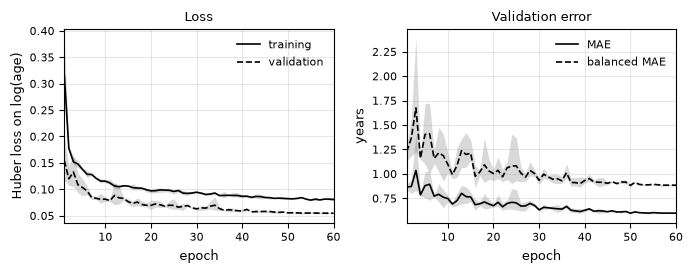

In [2]:
# learning curves of the three runs: the line is their mean, the band their range
curves = pd.concat([pd.read_csv(OUT / run / "learning_curve.csv") for run in RUNS.values()])
summary = curves.groupby("epoch").agg(["mean", "min", "max"])

fig, (ax_loss, ax_err) = plt.subplots(1, 2, figsize=(7, 2.8))
panels = [(ax_loss, {"train_loss": "training", "val_loss": "validation"}, "Huber loss on log(age)", "Loss"),
          (ax_err, {"val_MAE": "MAE", "val_balanced_MAE": "balanced MAE"}, "years", "Validation error")]
for ax, columns, ylabel, title in panels:
    for (column, label), style in zip(columns.items(), ["-", "--"]):
        s = summary[column]
        ax.plot(s.index, s["mean"], color="black", linestyle=style, linewidth=1.2, label=label)
        ax.fill_between(s.index, s["min"], s["max"], color="black", alpha=0.15, linewidth=0)
    ax.set(xlabel="epoch", ylabel=ylabel, title=title, xlim=(1, summary.index.max()))
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
fig.tight_layout()
save(fig, "cnn_learning_curves")
plt.show()


In [3]:
def load_predictions(split):
    # one row per child: id, age, ridge's prediction and each CNN run's, joined on id (never on row order)
    df = pd.read_csv(OUT / "ridge" / f"{split}_predictions.csv", dtype={"id": str}).rename(columns={"pred": "ridge"})
    for seed, run in RUNS.items():
        cnn = pd.read_csv(OUT / run / f"{split}_predictions.csv", dtype={"id": str})
        df = df.merge(cnn.rename(columns={"age": "age_cnn", "pred": f"CNN {seed}"}), on="id", validate="one_to_one")
        # CNN ages were saved as float32, ridge ages as float64, so compare with a tolerance
        assert np.allclose(df.age, df.age_cnn), f"{run} disagrees with ridge on a child's age"
        df = df.drop(columns="age_cnn")
    ages = split_ages(split)
    assert sorted(df.id) == sorted(ages.index), f"the files do not cover exactly the {split} children"
    assert np.allclose(df.age, ages[df.id]), "an age differs from the split file"
    return df

pred = {split: load_predictions(split) for split in SPLITS}
{split: len(df) for split, df in pred.items()}


{'val': 103, 'test': 104}

In [4]:
CNN_COLUMNS = [f"CNN {seed}" for seed in RUNS]
CNN_ROWS = [f"CNN, seed {seed}" for seed in RUNS]

def results_table(df):
    age = df.age.to_numpy()
    rows = {"predict training median": evaluate(age, np.full(len(age), TRAIN_MEDIAN)),
            "ridge": evaluate(age, df.ridge.to_numpy())}
    rows["predict training median"]["r"] = np.nan   # undefined for a constant prediction
    for column, row in zip(CNN_COLUMNS, CNN_ROWS):
        rows[row] = evaluate(age, df[column].to_numpy())
    table = pd.DataFrame(rows).T
    # the frozen protocol: the CNN's numbers are the mean over its three runs, not one averaged model
    table.loc["CNN, mean of 3 runs"] = table.loc[CNN_ROWS].mean()
    return table

tables = {}
for split in SPLITS:
    tables[split] = results_table(pred[split])
    tables[split].to_csv(TAB / f"results_{split}.csv")
    runs = tables[split].loc[CNN_ROWS]
    print(f"{split}: CNN runs range over MAE {runs['MAE'].min():.2f}-{runs['MAE'].max():.2f}, "
          f"balanced MAE {runs['balanced MAE'].min():.2f}-{runs['balanced MAE'].max():.2f}")
    display(tables[split].round(2))


val: CNN runs range over MAE 0.59-0.60, balanced MAE 0.87-0.89


,MAE,balanced MAE,<1,1-3,3-6,6-12,12+,r,R2
predict training median,2.98,4.37,2.47,1.18,1.63,5.51,11.07,NaN,-0.04
ridge,0.75,1.08,0.13,0.49,0.75,1.77,2.26,0.94,0.89
"CNN, seed 0",0.60,0.87,0.10,0.32,0.90,1.19,1.86,0.97,0.94
"CNN, seed 1",0.60,0.88,0.10,0.33,0.88,1.23,1.88,0.97,0.94
"CNN, seed 2",0.59,0.89,0.10,0.31,0.88,1.12,2.06,0.97,0.94
"CNN, mean of 3 runs",0.60,0.88,0.10,0.32,0.89,1.18,1.93,0.97,0.94


test: CNN runs range over MAE 0.70-0.74, balanced MAE 0.87-0.93


,MAE,balanced MAE,<1,1-3,3-6,6-12,12+,r,R2
predict training median,3.39,4.36,2.39,1.09,1.31,6.17,10.83,NaN,-0.12
ridge,0.86,1.12,0.19,0.27,1.23,1.39,2.51,0.94,0.88
"CNN, seed 0",0.70,0.87,0.16,0.26,1.02,1.21,1.68,0.97,0.93
"CNN, seed 1",0.74,0.93,0.17,0.27,1.06,1.24,1.89,0.96,0.92
"CNN, seed 2",0.70,0.87,0.16,0.26,1.03,1.17,1.73,0.97,0.93
"CNN, mean of 3 runs",0.71,0.89,0.16,0.26,1.04,1.20,1.77,0.96,0.93


In [5]:
def paired_bootstrap(age, err_cnn, err_ridge, B=10_000, seed=0):
    # children are drawn with replacement within each age group; one draw scores both models (paired)
    group = pd.cut(age, EDGES, right=False, labels=GROUPS).codes
    members = [np.flatnonzero(group == g) for g in range(len(GROUPS))]
    assert all(len(m) > 0 for m in members), "an age group has no children"
    rng = np.random.default_rng(seed)
    d_mae, d_bal = np.empty(B), np.empty(B)
    for b in range(B):
        draw = [rng.choice(m, size=len(m), replace=True) for m in members]
        drawn = np.concatenate(draw)
        d_mae[b] = err_cnn[drawn].mean() - err_ridge[drawn].mean()
        d_bal[b] = np.mean([err_cnn[d].mean() - err_ridge[d].mean() for d in draw])
    return d_mae, d_bal

boot = {}
for split in SPLITS:
    df, table = pred[split], tables[split]
    age = df.age.to_numpy()
    err_cnn = np.abs(df[CNN_COLUMNS].to_numpy() - age[:, None]).mean(axis=1)   # each child's error, averaged over the 3 runs
    err_ridge = np.abs(df.ridge.to_numpy() - age)
    d_mae, d_bal = paired_bootstrap(age, err_cnn, err_ridge)
    rows = {}
    for metric, d in [("MAE", d_mae), ("balanced MAE", d_bal)]:
        observed = table.loc["CNN, mean of 3 runs", metric] - table.loc["ridge", metric]
        low, high = np.percentile(d, [2.5, 97.5])
        rows[metric] = {"observed": observed, "2.5%": low, "97.5%": high, "share CNN worse": (d > 0).mean()}
    boot[split] = pd.DataFrame(rows).T
    boot[split]["clear"] = (boot[split]["97.5%"] < 0) | (boot[split]["2.5%"] > 0)   # the interval excludes 0
    boot[split].to_csv(TAB / f"bootstrap_{split}.csv")
    print(f"{split}: CNN minus ridge, in years (negative = CNN better)")
    display(boot[split].round(3))


val: CNN minus ridge, in years (negative = CNN better)


,observed,2.5%,97.5%,share CNN worse,clear
MAE,-0.152,-0.340,0.033,0.051,False
balanced MAE,-0.195,-0.612,0.200,0.176,False


test: CNN minus ridge, in years (negative = CNN better)


,observed,2.5%,97.5%,share CNN worse,clear
MAE,-0.149,-0.358,0.057,0.076,False
balanced MAE,-0.231,-0.502,0.056,0.054,False


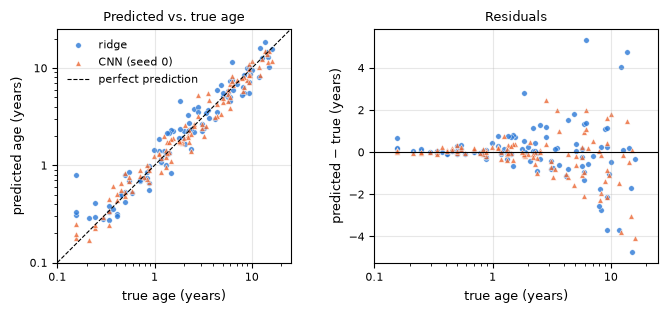

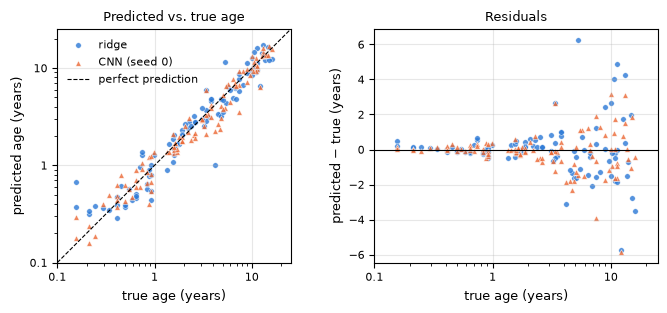

In [6]:
def comparison_figure(df):
    # ridge and one CNN run (seed 0, fixed beforehand) against true age; log age axis, since half the children are under 3
    age = df.age.to_numpy()
    fig, (ax_pred, ax_res) = plt.subplots(1, 2, figsize=(7, 3.2))
    for name, column, label in [("ridge", "ridge", "ridge"), ("CNN", "CNN 0", "CNN (seed 0)")]:
        style = dict(s=16, alpha=0.8, color=COLOR[name], marker=MARKER[name], edgecolor="white", linewidth=0.4, label=label)
        ax_pred.scatter(age, df[column], **style)
        ax_res.scatter(age, df[column] - age, **style)
    lims = (0.1, 25)
    ax_pred.plot(lims, lims, "k--", linewidth=0.8, label="perfect prediction")
    ax_pred.set(xscale="log", yscale="log", xlim=lims, ylim=lims, aspect="equal",
                xlabel="true age (years)", ylabel="predicted age (years)", title="Predicted vs. true age")
    ax_res.axhline(0, color="black", linewidth=0.8)
    ax_res.set(xscale="log", xlim=lims, xlabel="true age (years)", ylabel="predicted − true (years)", title="Residuals")
    for ax in (ax_pred, ax_res):
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.grid(alpha=0.3)
    ax_pred.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax_pred.legend(frameon=False, loc="upper left")
    fig.tight_layout()
    return fig

for split in SPLITS:
    fig = comparison_figure(pred[split])
    save(fig, f"cnn_vs_ridge_{split}")
    plt.show()
